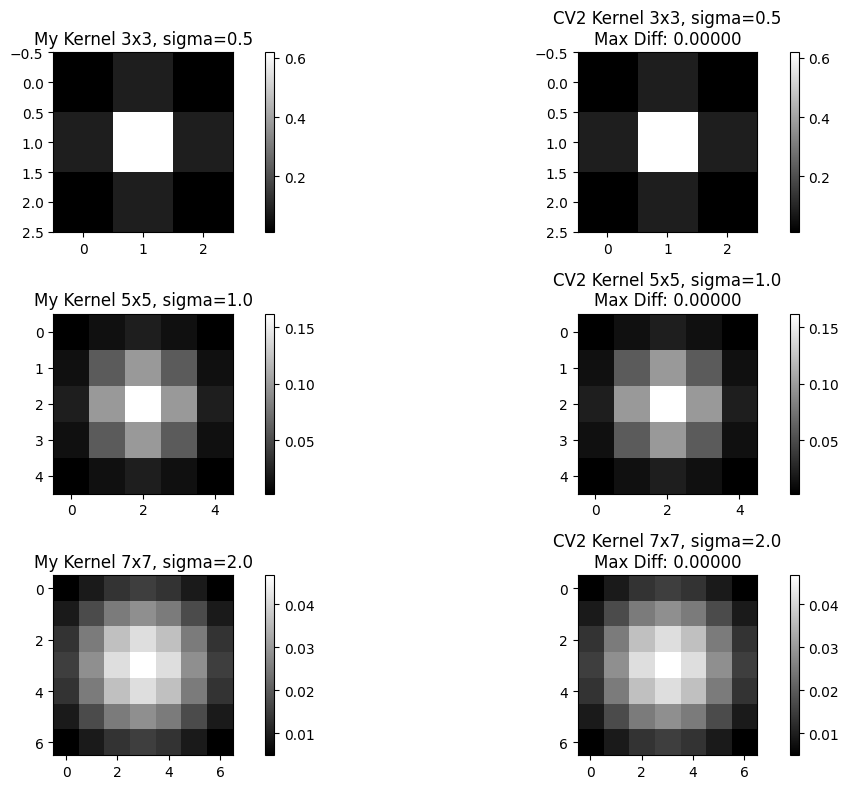

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def my_gaussian_kernel(ksize, sigma):
    ax = np.arange(-ksize // 2 + 1, ksize // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)
    return kernel

def opencv_gaussian_kernel(ksize, sigma):
    k1d = cv2.getGaussianKernel(ksize, sigma)
    kernel_2d = np.outer(k1d, k1d)
    return kernel_2d

params = [(3, 0.5), (5, 1.0), (7,2.0)]

plt.figure(figsize=(12, 8))
plot_idx = 1

for ksize, sigma in params:
    my_k = my_gaussian_kernel(ksize, sigma)
    cv_k = opencv_gaussian_kernel(ksize, sigma)
    diff = np.max(np.abs(my_k - cv_k))

    plt.subplot(3, 2, plot_idx)
    plt.imshow(my_k, cmap="gray")
    plt.title(f'My Kernel {ksize}x{ksize}, sigma={sigma}')
    plt.colorbar()
    plot_idx += 1

    plt.subplot(3, 2, plot_idx)
    plt.imshow(cv_k, cmap="gray")
    plt.title(f'CV2 Kernel {ksize}x{ksize}, sigma={sigma}\nMax Diff: {diff:.5f}')
    plt.colorbar()
    plot_idx += 1
plt.tight_layout()
plt.show()

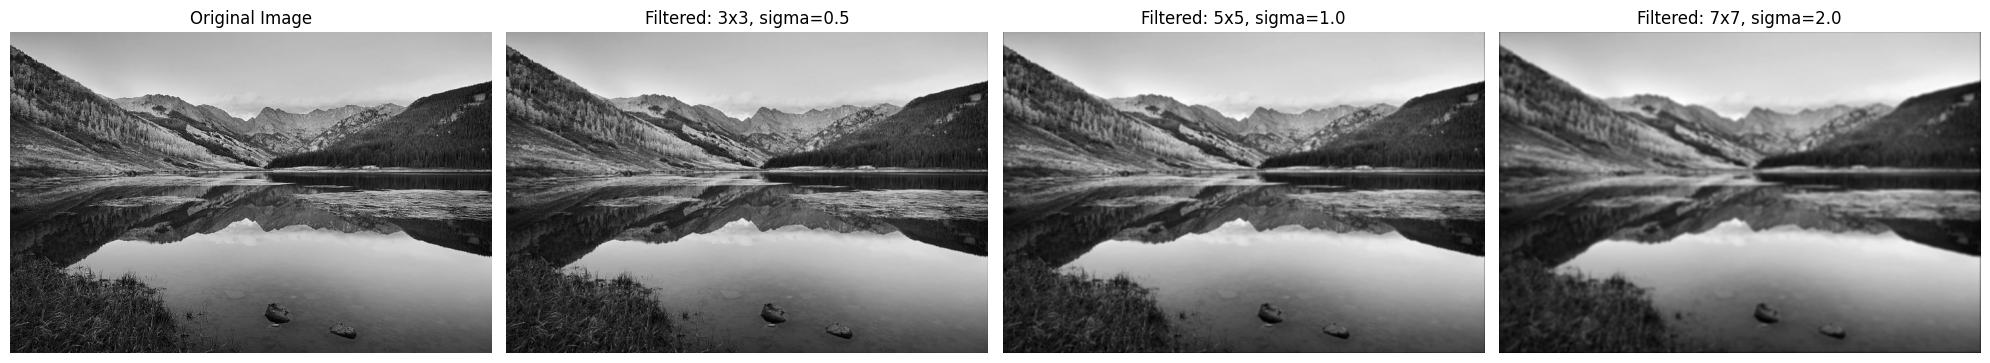

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def my_manual_filter(image, kernel):
    h, w = image.shape
    k_h, k_w = kernel.shape

    pad_h = k_h // 2
    pad_w = k_w // 2

    padded_img = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant')
    output = np.zeros_like(image, dtype=np.float32)

    for i in range(h):
        for j in range(w):
            region = padded_img[i :i + k_h, j : j + k_w]
            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)

img = cv2.imread('picture.jpg', 0)
params = [(3, 0.5), (5, 1.0), (7,2.0)]

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis('off')

for idx, (ksize, sigma) in enumerate(params):
    k = my_gaussian_kernel(ksize, sigma)
    filtered_img = my_manual_filter(img, k)

    plt.subplot(1, 4, idx + 2)
    plt.imshow(filtered_img, cmap="gray")
    plt.title(f'Filtered: {ksize}x{ksize}, sigma={sigma}')
    plt.axis('off')

plt.tight_layout()
plt.show()

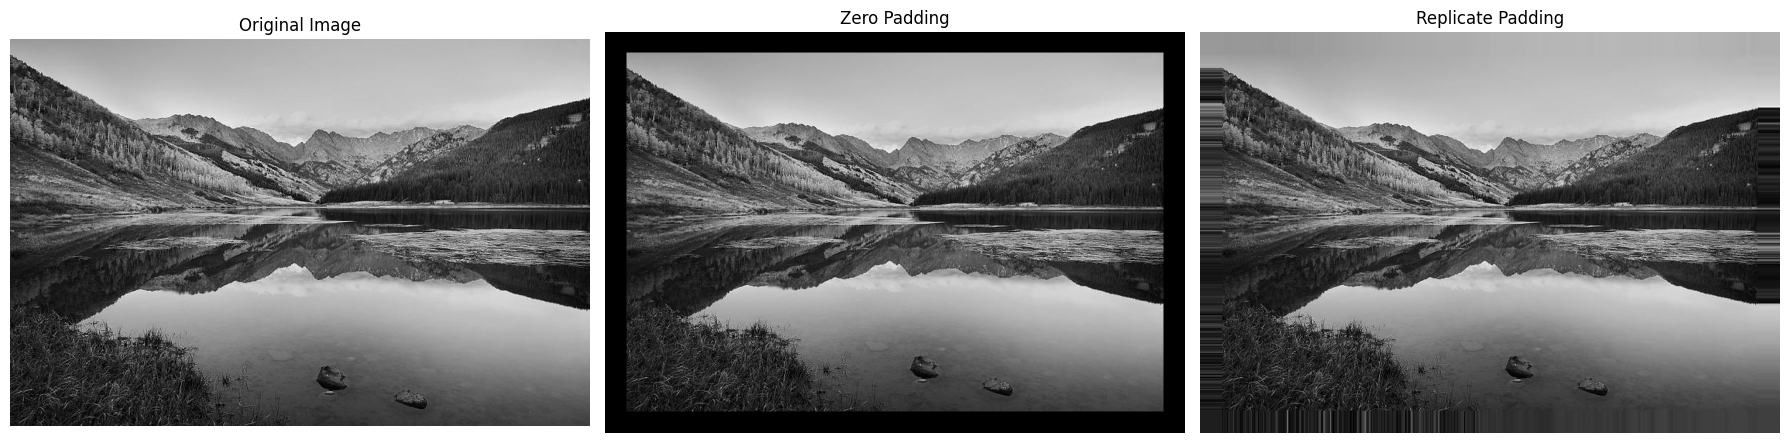

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('picture.jpg', 0)

pad_size = 30
pad_zero = np.pad(img, ((pad_size, pad_size), (pad_size, pad_size)), mode='constant')
pad_edge = np.pad(img, ((pad_size, pad_size), (pad_size, pad_size)), mode='edge')

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(pad_zero, cmap="gray")
plt.title("Zero Padding")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(pad_edge, cmap="gray")
plt.title("Replicate Padding")
plt.axis('off')

plt.tight_layout()
plt.show()